**Preview for the later RNA + ATAC session. The current main practical is [RNA-only](02_greta_evaluation.ipynb).**

# Evaluate a GRN: what do the different GRETA tasks mean?

**Main practical · 60–90 minutes · Python 3.12**

Our goal is the task-level figure from the [GRETA evaluation tutorial](https://gretapy.readthedocs.io/en/latest/notebooks/eval.html):

```python
gt.pl.ranking(res, level="task")
```

We will generate simple networks briefly, then spend most of the session interpreting the evaluation evidence. The live benchmark uses the package's **synthetic paired RNA+ATAC PBMC-like example** and native gretapy metrics. It covers six task types, eleven database/subtask columns and all four evaluation classes. A separate, stored published-result panel shows all eleven task types from the larger benchmark.

The toy ranking is an instructional result, not a claim about which method is biologically best. Students with their own GRNs can replace the example inputs; see the final section and [README](RNA_ATAC_PREVIEW.md).

## 1. Start an interactive session

Use the same environment as the earlier practical. No new analysis packages are required. Select its Python kernel, then run cells in order with **Shift+Enter**. See [setup instructions](RNA_ATAC_PREVIEW.md) for JupyterLab and the macOS OpenMP setting.

The default profile downloads about **84 MB once**, mostly KnockTF, and caches roughly 170 MB locally. Set `PROFILE = "quick"` below to omit the mechanistic download; the reduced plot will then contain three classes. The small published-score snapshot is bundled and needs no benchmark-data download.

In [1]:
from pathlib import Path
import os
import sys
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cosmos-grn-matplotlib"))
os.environ.setdefault("NUMBA_CACHE_DIR", str(Path(tempfile.gettempdir()) / "cosmos-grn-numba"))
HERE = next((p for p in [Path.cwd(), Path.cwd() / "GRN_comparison"]
             if (p / "greta_benchmark.py").exists()), None)
if HERE is None:
    raise RuntimeError("Open from the repository root or GRN_comparison folder.")
sys.path.insert(0, str(HERE))

import gretapy as gt
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from greta_benchmark import (
    GretaConfig, QUICK_METRICS, TEACHING_METRICS, DIAGNOSTICS,
    configure_cache, load_dataset, build_networks, validate_grn,
    evaluate_networks, comparable_results, published_results, save_evaluation,
)
configure_cache()
print("gretapy", gt.__version__)

/private/tmp/cosmos-grn-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


gretapy 0.0.3


In [2]:
PROFILE = "teaching"       # "quick" skips KnockTF / TF Scoring
DATA_PATH = None           # or Path("/path/to/your_prepared.h5mu")
CONTEXT = "PBMC"            # change to a relevant context for your own data
OWN_GRNS = {}              # e.g. {"MyGRN": Path("/path/to/network.tsv")}

config = GretaConfig(n_cells=180, seed=42, edges_per_tf=5, profile=PROFILE)
mdata = load_dataset(config, dataset_path=DATA_PATH)
terms = gt.get_terms(CONTEXT)
print(mdata)
display(mdata.obs[["celltype"]].value_counts().rename("cells"))

MuData object with n_obs × n_vars = 180 × 93
  obs:	'celltype'
  2 modalities
    rna:	180 × 30
      layers:	None
    atac:	180 × 63
      layers:	None


celltype
B cell      60
T cell      60
Monocyte    60
Name: cells, dtype: int64

## 2. Get a data-driven network to compare with CollecTRI

The network is a convenient input to this lesson; learning a full inference pipeline is a separate practical.

1. Identify measured transcriptional regulators that have enough eligible CollecTRI targets for a comparison.
2. Use **training cells only** to correlate TF RNA with target RNA. Pearson measures linear association; Spearman compares ranks.
3. Attach one accessible ATAC region overlapping each target's annotated promoter.
4. Keep a few strong TF–target associations. Build a prior network from curated CollecTRI pairs on the same feature map, and a random control.

Gretapy's public `gt.mt.correlation` and `gt.mt.lit_grn` supply the candidates. Our helper matches TF identities and outgoing-edge budgets across the four demo networks. This caps the number of unique targets per TF at five, requiring at least three eligible prior targets. The default produces seven TFs and 31 edges in each graph.

Correlation does not prove direct regulation. Direction comes from identifying the source as a TF, and the promoter assignment is an annotation assumption. These baselines do not learn a distal enhancer network or test TF binding. The package's hardcoded toy GRN is discarded.

The inference cells are exactly the training partition used by gretapy's Omics tasks (stratified 33% test split, seed 42). Test cells therefore do not choose demo edges.

In [3]:
networks, inference_split, promoter_map = build_networks(mdata, config)
for name, path in OWN_GRNS.items():
    if name in networks:
        raise ValueError("Choose a distinct name for your own GRN.")
    networks[name] = validate_grn(pd.read_csv(path, sep=None, engine="python"), mdata)

display(gt.tl.stats(networks))
display(networks["Pearson"].head())
display(inference_split.groupby("partition").size().rename("cells"))

,name,n_sources,n_cres,n_targets,n_edges,mean_regulon_size
0,Pearson,7,15,15,31,4.428571
1,Spearman,7,18,18,31,4.428571
2,CollecTRI,7,18,18,31,4.428571
3,Random,7,18,18,31,4.428571


,source,cre,target,score
0,CEBPA,chr17-7578991-7579491,CD68,0.876377
1,CEBPA,chr2-112836816-112837316,IL1B,0.869974
2,CEBPA,chr5-140633700-140634200,CD14,0.857802
3,EBF1,chr11-60455346-60455846,MS4A1,0.826083
4,EBF1,chr12-4269271-4269771,CCND2,0.834562


partition
test      60
train    120
Name: cells, dtype: int64

## 3. Decide what evidence to use

GRETA separates **classes**, **tasks**, and **databases/subtasks**. A task can have several columns in the final plot: for example, Omics has three prediction directions.

The default evaluates ENCODE regulatory regions and Blacklist; HPA and TF-Marker regulator lists; IntAct and Europe PMC TF pairs; Hallmark gene sets; all three Omics directions; and KnockTF TF Scoring. Context terms restrict relevant resources to blood/immune evidence.

We also compute two diagnostic checks—Promoters and CollecTRI agreement—but exclude them from ranking because these references were used to construct our baselines. The compatibility helper repairs label routing in pinned gretapy 0.0.3 and checks that every requested metric returned; it retains native model algorithms and score formulas. Undefined constant-response correlations are excluded with coverage counts.

In [4]:
metrics = list(TEACHING_METRICS if PROFILE == "teaching" else QUICK_METRICS)
catalog = gt.show_metrics(organism="hg38")
display(catalog[catalog.db.isin(metrics)].sort_values(["category", "metric", "db"]))
print("Separate diagnostics:", ", ".join(DIAGNOSTICS))

,category,metric,db
1,Genomic,CREs,ENCODE Blacklist
2,Genomic,CREs,ENCODE CREs
11,Literature,TF Markers,HPA
12,Literature,TF Markers,TF-Marker
13,Literature,TF Pairs,Europe PMC
14,Literature,TF Pairs,IntAct
17,Mechanistic,TF Scoring,KnockTF (scoring)
18,Predictive,Gene Sets,Hallmarks
22,Predictive,Omics,CRE ~ TFs
23,Predictive,Omics,Gene ~ CREs


Separate diagnostics: Promoters, CollecTRI


### What does an F₀.₁ score summarize?

Precision asks how many evaluated predictions pass a task's test. Recall asks how much of its reference or measured universe those successes cover. Their counted unit depends on the task: it can be an edge, gene, perturbation experiment, or steady state.

\[
F_{0.1}=\frac{1.01\,P\,R}{0.01\,P+R}.
\]

This strongly emphasizes precision. The β=0.1 parameter is squared in the formula; it is not a simple tenfold weight. Higher means better **under that task's definition**, not a universal percentage of correct regulatory edges.

Read precision, recall and coverage together. A zero with eligible tests is different from no usable evidence. The helper records Omics and TF Scoring coverage; untested results become missing values, not zero scores.

In [5]:
# This calls the native gt.tl.benchmark with explicit tasks and a loaded MuData.
# The full benchmark across all datasets/databases is deliberately not launched.
res_all, coverage = evaluate_networks(
    mdata, networks, terms=terms,
    metrics=metrics + list(DIAGNOSTICS),
    dataset_name="Toy PBMC" if DATA_PATH is None else Path(DATA_PATH).stem,
)
display(res_all[["name", "class", "task", "db", "precision", "recall", "f01"]].head(12))

,name,class,task,db,precision,recall,f01
0,Pearson,Literature,Reference GRN,CollecTRI,0.419355,0.200000,0.414850
1,Pearson,Genomic,CREs,ENCODE CREs,0.933333,0.215385,0.903514
2,Pearson,Predictive,Omics,Gene ~ CREs,1.000000,0.500000,0.990196
3,Pearson,Literature,TF Pairs,Europe PMC,0.000000,0.000000,0.000000
4,Pearson,Predictive,Omics,CRE ~ TFs,1.000000,0.238095,0.969290
5,Pearson,Literature,TF Markers,HPA,1.000000,0.700000,0.995775
6,Pearson,Mechanistic,TF Scoring,KnockTF (scoring),0.000000,0.000000,0.000000
7,Pearson,Predictive,Omics,Gene ~ TFs,1.000000,0.500000,0.990196
8,Pearson,Genomic,CREs,Promoters,1.000000,0.483871,0.989549
9,Pearson,Literature,TF Markers,TF-Marker,0.857143,0.666667,0.854725


## 4. Interpret each class before looking at the overall ranking

### Genomic: are the proposed regulatory elements supported?

- **TF Binding:** do TF–CRE links overlap binding-reference intervals for that TF? Binding supports physical occupancy, not necessarily functional regulation.
- **CREs:** are network regions supported by regulatory annotations? ENCODE CREs rewards overlap; **Blacklist rewards avoiding problematic regions**. These annotation types answer different questions.
- **CRE to Gene:** are the proposed region–target links supported by external target-associated intervals, such as eQTL-linked regions? This tests region-to-gene assignment rather than TF action.

Our live run evaluates only CRE annotations. TF Binding and CRE-to-Gene are shown in the published panel below; they require extra reference downloads if recomputed. Promoter overlap would be nearly guaranteed by our construction, so it is a diagnostic, not an independent achievement.

In [6]:
display(res_all.query("`class` == 'Genomic'")
        [["name", "task", "db", "precision", "recall", "f01"]])

,name,task,db,precision,recall,f01
1,Pearson,CREs,ENCODE CREs,0.933333,0.215385,0.903514
8,Pearson,CREs,Promoters,1.000000,0.483871,0.989549
11,Pearson,CREs,ENCODE Blacklist,1.000000,0.194805,0.960685
14,Spearman,CREs,ENCODE CREs,0.944444,0.269841,0.921632
21,Spearman,CREs,Promoters,1.000000,0.600000,0.993443
24,Spearman,CREs,ENCODE Blacklist,1.000000,0.225000,0.967021
27,CollecTRI,CREs,ENCODE CREs,1.000000,0.300000,0.977419
34,CollecTRI,CREs,Promoters,1.000000,0.600000,0.993443
37,CollecTRI,CREs,ENCODE Blacklist,1.000000,0.225000,0.967021
40,Random,CREs,ENCODE CREs,0.944444,0.278689,0.922622


### Predictive: does the topology select useful predictors and functions?

**Omics** fits a common model with network-selected predictors, then tests positive predicted–observed correlation on held-out cells:

- `Gene ~ TFs`: target RNA from its incoming TF RNA.
- `Gene ~ CREs`: target RNA from linked region accessibility.
- `CRE ~ TFs`: region accessibility from linked TF RNA.

Native GRETA uses up to five strongest incoming predictors, XGBoost, and a significance criterion for held-out Spearman correlation. Precision is successful features / tested features; recall is successful features / all measured features. The implementation excludes zero-valued responses and requires at least ten usable test observations. It does not report R² or count correct edges.

**Gene Sets** compares pathways active in the expression data with pathways enriched among TF target sets. It tests broad functional coverage, not individual regulatory edges or a fitted expression prediction.

**Discuss:** Could cell identity explain apparently excellent prediction in this planted toy example? Because the demo networks share one promoter per target, `Gene ~ CREs` largely reflects included genes and promoter–RNA association; it cannot identify the best TF assignments on its own.

In [7]:
display(res_all.query("`class` == 'Predictive'")
        [["name", "task", "db", "precision", "recall", "f01"]])
display(coverage[coverage.db.str.contains(" ~ ", regex=False)])

,name,task,db,precision,recall,f01
2,Pearson,Omics,Gene ~ CREs,1.000000,0.500000,0.990196
4,Pearson,Omics,CRE ~ TFs,1.000000,0.238095,0.969290
7,Pearson,Omics,Gene ~ TFs,1.000000,0.500000,0.990196
10,Pearson,Gene Sets,Hallmarks,0.000000,0.000000,0.000000
15,Spearman,Omics,Gene ~ CREs,0.944444,0.566667,0.938251
17,Spearman,Omics,CRE ~ TFs,0.944444,0.269841,0.921632
20,Spearman,Omics,Gene ~ TFs,1.000000,0.600000,0.993443
23,Spearman,Gene Sets,Hallmarks,0.000000,0.000000,0.000000
28,CollecTRI,Omics,Gene ~ CREs,0.944444,0.566667,0.938251
30,CollecTRI,Omics,CRE ~ TFs,0.777778,0.222222,0.758991


,name,db,status,n_tested,n_hits,n_skipped_constant_response,n_eligible
2,Pearson,Gene ~ CREs,evaluated,15.0,15.0,0.0,NaN
4,Pearson,CRE ~ TFs,evaluated,15.0,15.0,0.0,NaN
7,Pearson,Gene ~ TFs,evaluated,15.0,15.0,0.0,NaN
15,Spearman,Gene ~ CREs,evaluated,18.0,17.0,0.0,NaN
17,Spearman,CRE ~ TFs,evaluated,18.0,17.0,0.0,NaN
20,Spearman,Gene ~ TFs,evaluated,18.0,18.0,0.0,NaN
28,CollecTRI,Gene ~ CREs,evaluated,18.0,17.0,0.0,NaN
30,CollecTRI,CRE ~ TFs,evaluated,18.0,14.0,0.0,NaN
33,CollecTRI,Gene ~ TFs,evaluated,18.0,11.0,0.0,NaN
41,Random,Gene ~ CREs,evaluated,18.0,17.0,0.0,NaN


### Literature: does the network recover known regulators and relationships?

- **TF Markers:** checks the source TF identities against relevant marker lists. It ignores target wiring. Our matched source sets should tie.
- **TF Pairs:** asks whether TFs with unexpectedly overlapping target sets agree with known TF interaction pairs. It does not simply count directed TF→TF edges.
- **Reference GRN:** checks directed TF–target agreement with a curated reference. An absent reference edge is not established biological falsity. CollecTRI evaluated against CollecTRI is circular.

A high literature score may reflect how a method was built, how well studied its regulators are, and the reference context. Check reuse of evidence before interpreting it as independent validation.

In [8]:
display(res_all.query("`class` == 'Literature'")
        [["name", "task", "db", "precision", "recall", "f01"]])

,name,task,db,precision,recall,f01
0,Pearson,Reference GRN,CollecTRI,0.419355,0.200000,0.414850
3,Pearson,TF Pairs,Europe PMC,0.000000,0.000000,0.000000
5,Pearson,TF Markers,HPA,1.000000,0.700000,0.995775
9,Pearson,TF Markers,TF-Marker,0.857143,0.666667,0.854725
12,Pearson,TF Pairs,IntAct,0.000000,0.000000,0.000000
13,Spearman,Reference GRN,CollecTRI,0.290323,0.138462,0.287204
16,Spearman,TF Pairs,Europe PMC,0.000000,0.000000,0.000000
18,Spearman,TF Markers,HPA,1.000000,0.700000,0.995775
22,Spearman,TF Markers,TF-Marker,0.857143,0.666667,0.854725
25,Spearman,TF Pairs,IntAct,0.000000,0.000000,0.000000


### Mechanistic: does the network support functional predictions?

- **TF Scoring:** uses the signed regulon to estimate activity from an external KnockTF knockdown expression profile. A successful test detects a significant decrease in the perturbed TF's activity. This tests regulon-based detection of TF loss, not every edge individually.
- **Perturbation Forecasting:** fits coefficients using the graph support, propagates a knockout, and compares predicted changes with external perturbation responses. It refits coefficients rather than directly testing the original edge weights. Sufficient connected regulators, response genes and eligible perturbations are needed.
- **Steady State Simulation:** turns a signed TF–TF network into Boolean rules and checks whether simulated steady states match cell-type marker patterns. This tests a simplified dynamical model, not observed biological dynamics.

The live example runs **TF Scoring**. Forecasting and Boolean simulation are covered by the published panel; this tiny graph is poorly suited to their coverage requirements. TF Scoring needs valid regulatory sign interpretation: a positive association/confidence score is not automatically an activating effect.

**Discuss:** How should you interpret zero significant TF-loss detections if only a few eligible experiments are available? What would a convincing independent perturbation evaluation require?

In [9]:
display(res_all.query("`class` == 'Mechanistic'")
        [["name", "task", "db", "precision", "recall", "f01"]])
display(coverage[coverage.db.eq("KnockTF (scoring)")])

,name,task,db,precision,recall,f01
6,Pearson,TF Scoring,KnockTF (scoring),0.0,0.0,0.0
19,Spearman,TF Scoring,KnockTF (scoring),0.0,0.0,0.0
32,CollecTRI,TF Scoring,KnockTF (scoring),0.0,0.0,0.0
45,Random,TF Scoring,KnockTF (scoring),0.0,0.0,0.0


,name,db,status,n_tested,n_hits,n_skipped_constant_response,n_eligible
6,Pearson,KnockTF (scoring),evaluated,2.0,0.0,NaN,3.0
19,Spearman,KnockTF (scoring),evaluated,2.0,0.0,NaN,3.0
32,CollecTRI,KnockTF (scoring),evaluated,2.0,0.0,NaN,3.0
45,Random,KnockTF (scoring),evaluated,2.0,0.0,NaN,3.0


## 5. Produce and read the requested task-ranking figure

Remove the construction/self-reference diagnostics. If a method has no usable evidence for a database/subtask, that column is excluded for **all** methods in the comparable ranking. The complete results and exclusions remain available.

This controls whether methods were evaluated on the same columns. It does not make their numbers of tested features identical; inspect coverage separately.

Ranked: 11 columns, 6 task types, 4 classes


,name,db,reason
0,Pearson,CollecTRI,Construction/self-reference diagnostic; exclud...
1,Spearman,CollecTRI,Construction/self-reference diagnostic; exclud...
2,CollecTRI,CollecTRI,Construction/self-reference diagnostic; exclud...
3,Random,CollecTRI,Construction/self-reference diagnostic; exclud...
4,Pearson,Promoters,Construction/self-reference diagnostic; exclud...
5,Spearman,Promoters,Construction/self-reference diagnostic; exclud...
6,CollecTRI,Promoters,Construction/self-reference diagnostic; exclud...
7,Random,Promoters,Construction/self-reference diagnostic; exclud...


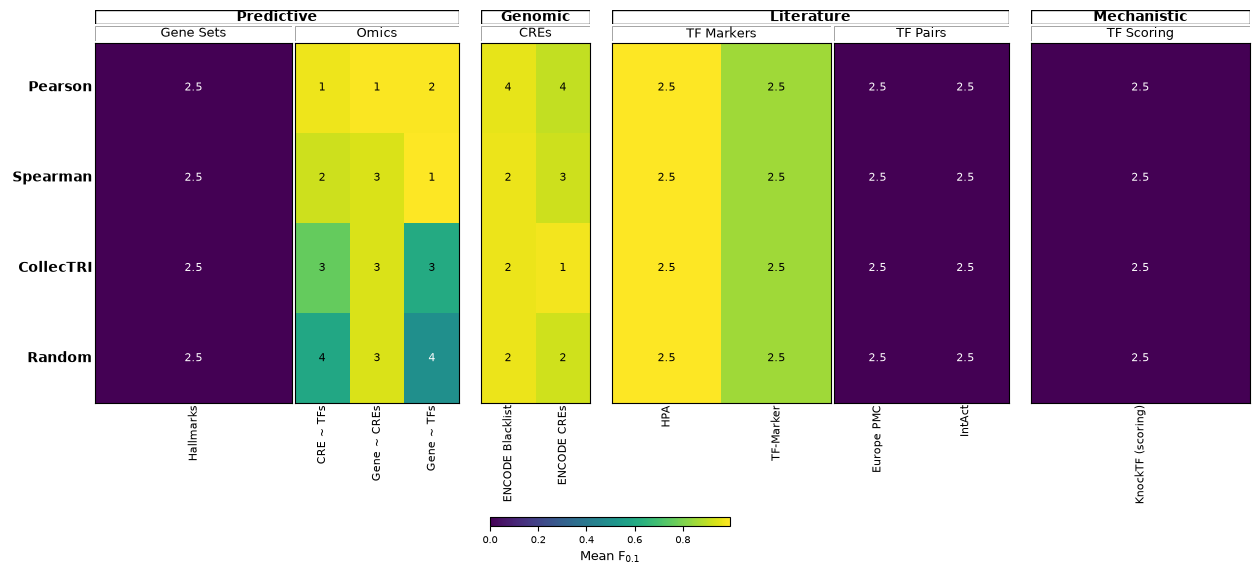

In [10]:
res, excluded = comparable_results(res_all)
print(f"Ranked: {res.db.nunique()} columns, {res.task.nunique()} task types, {res['class'].nunique()} classes")
display(excluded[["name", "db", "reason"]])
gt.pl.ranking(res, level="task", figsize=(16, 6))

### How to read the figure

- **Rows:** methods, ordered by their aggregate score.
- **Columns:** reference databases or prediction subtasks, grouped into tasks and classes.
- **Colors:** mean raw F₀.₁ values. Higher values are better under each column's definition.
- **Numbers:** ranks within each column. **1 is best**; ties have average ranks, so four tied methods receive 2.5.
- **Missing:** unavailable evidence, rather than evidence of zero performance.

The overall ordering first averages databases within tasks, tasks within classes, and class scores with equal default weights within each dataset, then averages datasets. Changing weights changes the question being asked. A rank difference is not a statistical significance test.

In particular, a large color difference between columns does not establish that one biological task is easier or more important: their units and reference coverage differ.

In [ ]:
display(gt.tl.ranking(res))
# A prespecified task emphasis changes the aggregate score, not the underlying results.
display(gt.tl.ranking(res, metric_weights={
    "predictive": 1, "genomic": 1, "literature": 1, "mechanistic": 0,
}))

## 6. Read the full published task panel

The authors' stored benchmark table lets us inspect all eleven task types and the broader collection of reference databases. This is a small **precomputed, attributed result snapshot** loaded through `gt.ds.read_metrics()`. It is not a recomputation of the large experiment and contains no imaginary method.

Keep it separate from our live toy results. A method scored on a different dataset or under different inference/evaluation conditions cannot be compared fairly by simply appending its row to this table.

In [ ]:
paper_res = published_results()
print(f"Published table: {paper_res.name.nunique()} methods; "
      f"{paper_res.dataset.nunique()} datasets; {paper_res.task.nunique()} task types")
gt.pl.ranking(paper_res, level="task")

Use [TASKS.md](RNA_ATAC_TASKS.md) as a reading guide for the additional TF Binding, CRE-to-Gene, Perturbation Forecasting and Steady State Simulation columns. The paper panel also contains a Reference GRN task, which we excluded from our own aggregate because our CollecTRI comparator uses the same source.

**Discuss:** Find a method that performs well on a predictive task but poorly on a mechanistic task. What distinct evidence does each task provide? What missing measurements would prevent you from evaluating a student's network on those same columns?

## 7. Save results and substitute a student's GRN

The helper saves native scores, coverage, exclusions, the inference split, edge lists, aggregate ranking and task/class figures. It does not rerun the evaluation.

In [ ]:
output = save_evaluation(
    res_all, coverage, networks, inference_split, promoter_map,
    config, output_dir=HERE / "results" / "greta_notebook",
    metadata="Synthetic toy PBMC" if DATA_PATH is None else str(DATA_PATH), terms=terms,
)
print("Saved to", output.resolve())

### Bringing your own single-cell RNA + ATAC GRN

In the configuration cell, set `DATA_PATH` to your prepared **human hg38 MuData** with `rna` and `atac`, aligned cells, nonnegative normalized values, and `mdata.obs['celltype']`. Set `CONTEXT` to the relevant context, or supply a tailored terms dictionary rather than using PBMC terms for unrelated tissue. For large data, prepare a manageable classroom subset first.

Set `OWN_GRNS = {"MyGRN": Path("/path/to/network.tsv")}`. The table must have `source`, `cre`, `target`, and numeric `score`; names must match the modalities, with regions formatted `chrX-start-end`. Use actual matched measurements, not invented chromatin features. Check signed effects versus unsigned confidence scores before interpreting mechanistic tasks.

The four demo baselines have matched budgets. A student graph retains its supplied size and source set: inspect those differences, agree on a comparable edge selection and record the measured universe before making performance claims. If the supplied GRN was inferred from all cells, the native Omics split does not retroactively protect its topology from test information. An independent inference/evaluation split or independent data provides stronger validation.

### Interpretation exercises

1. Explain why TF-marker scores tie while target prediction differs.
2. Distinguish a zero score from a task with no usable observations. Locate the supporting coverage counts.
3. Explain why Promoters and CollecTRI agreement are excluded from our ranking.
4. Keep the existing `mdata` fixed, import `replace` from `dataclasses`, and call `build_networks(mdata, replace(config, seed=43))`. This changes edge sampling without regenerating toy data. Which conclusions remain stable?
5. Choose evaluation tasks and class weights based on the biological use of the GRN, before inspecting rankings.
6. For a student's network, state what each evaluated task supports, what it cannot establish, and which important tasks remain untested.

The original [NCI60 notebook](01_grn_comparison.ipynb) remains available as an optional RNA-only extension. Its custom Ridge scores are a different prediction exercise and should not be pooled with native GRETA F₀.₁ scores.